# Clasificación del no uso de internet

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from scientific_audit import evaluate, sha
pd.set_option('display.precision',9)
def audit(phase):
    with threadpool_limits(limits=4): record=evaluate(phase)
    display(pd.DataFrame(record['checks']))
    print('Controles ejecutados:',len(record['checks']),'| Estado:',record['status'])
    print(record['evaluation_note'])
    return record['detail']
def table(name): display(pd.read_csv(ROOT/'reports/tables'/name))
def figure(name):
    path=ROOT/'reports/figures'/name
    print('Figura:',name,'| SHA-256:',sha(path))
    display(Image(filename=str(path)))
print('Evaluación de modelos y controles de integridad científica')


Evaluación de modelos y controles de integridad científica


## Método y alcance

Se recalculan predicciones de los cuatro modelos guardados, alineadas por índice y orden. Se verifican columnas, preprocesamiento, pesos, calibración y métricas. La comprobación de calibración reajusta únicamente la sigmoide sobre las predicciones OOF originales de desarrollo. No utiliza prueba. Los clasificadores se mantienen congelados; el entrenamiento completo de 200 ajustes se reproduce y compara aparte. El ganador se seleccionó por AP de cinco folds GroupKFold; las transformaciones se ajustaron dentro de cada fold. Umbral fijo: 0.5. La prueba fue observada anteriormente: esta evaluación es retrospectiva, no una validación externa inédita.

${PROJECT_ROOT}/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,name,passed
0,test_prediction_order,True
1,oof_development_order,True
2,test_target,True
3,test_weights,True
4,oof_target,True
...,...,...
86,unweighted_CatBoost_recall,True
87,unweighted_CatBoost_brier,True
88,unweighted_CatBoost_specificity,True
89,best_bundle_predictions,True


Controles ejecutados: 91 | Estado: passed
Evaluación retrospectiva sobre una partición de prueba previamente examinada; los resultados requieren validación externa independiente.
Ganador: CatBoost | Umbral: 0.5


,modelo,roc_auc,average_precision,pr_auc_trapezoidal,f1_macro,precision,recall,brier,specificity
0,Logística,0.815614131,0.585869130,0.585244785,0.680088429,0.649656382,0.368829185,0.128950167,0.943892053
1,Random Forest,0.814107256,0.585039573,0.584410490,0.674373021,0.643271568,0.358374388,0.129366712,0.943937956
2,XGBoost,0.817426561,0.595340404,0.594755289,0.688293704,0.657350544,0.384628899,0.128227327,0.943443369
3,CatBoost,0.820356650,0.601272493,0.600665989,0.693293954,0.690898863,0.381180843,0.127282458,0.951893275


,modelo,config,parametros,ap_cv_media,ap_cv_sd,auc_cv_media,f1_cv_media,estrategia_peso,segundos
0,CatBoost,0,"{""depth"": 3, ""l2_leaf_reg"": 3}",0.593465535,0.010856842,0.818595916,0.699880584,class,2.603240167
1,XGBoost,1,"{""max_depth"": 3, ""min_child_weight"": 1, ""reg_l...",0.593073633,0.016343451,0.817087280,0.690111392,uniform,1.203861208
2,Logística,1,"{""C"": 0.03}",0.588552190,0.025634229,0.816913979,0.670693522,uniform,0.172765083
3,Random Forest,0,"{""max_depth"": 8, ""min_samples_leaf"": 10, ""max_...",0.580912634,0.024842249,0.807852073,0.631638469,uniform,1.826540916


,modelo,seleccionado_cv,roc_auc,average_precision,pr_auc_trapezoidal,f1_macro,precision,recall,brier,specificity,brier_sin_calibrar,f1_macro_no_ponderado,auc_no_ponderado,roc_auc_no_ponderado,average_precision_no_ponderado,pr_auc_trapezoidal_no_ponderado,precision_no_ponderado,recall_no_ponderado,brier_no_ponderado,specificity_no_ponderado
0,Logística,False,0.815614131,0.585869130,0.585244785,0.680088429,0.649656382,0.368829185,0.128950167,0.943892053,0.128959665,0.714428601,0.839045954,0.839045954,0.656319273,0.656044236,0.663974152,0.472957422,0.132976640,0.919066148
1,Random Forest,False,0.814107256,0.585039573,0.584410490,0.674373021,0.643271568,0.358374388,0.129366712,0.943937956,0.131097309,0.720222229,0.832680795,0.832680795,0.654111348,0.653828268,0.660990712,0.491369390,0.134128472,0.914785992
2,XGBoost,False,0.817426561,0.595340404,0.594755289,0.688293704,0.657350544,0.384628899,0.128227327,0.943443369,0.128460448,0.722367537,0.840311329,0.840311329,0.666466599,0.666216702,0.674641148,0.486766398,0.131711347,0.920622568
3,CatBoost,True,0.820356650,0.601272493,0.600665989,0.693293954,0.690898863,0.381180843,0.127282458,0.951893275,0.161579669,0.717705492,0.840619837,0.840619837,0.665313395,0.665056904,0.686440678,0.466052934,0.131657431,0.928015564


,modelo,estrategia,ap_cv_media,ap_oof_no_ponderada,brier_oof_ponderado,ap_oof_peso_educacion,segundos
0,Logística,uniform,0.587466558,0.663589685,0.133100079,0.596696880,0.161149000
1,Logística,population,0.585403241,0.656498501,0.133429551,0.594859178,0.174047750
2,Logística,class,0.587352046,0.663119546,0.162729554,0.596781837,0.179005625
3,Logística,population_class,0.584980495,0.656331206,0.176369258,0.594982848,0.182871417
4,Random Forest,uniform,0.580912634,0.658025278,0.136463378,0.590134708,1.891699791
5,Random Forest,population,0.575313480,0.655244309,0.137719039,0.585598087,1.666161542
6,Random Forest,class,0.577423111,0.656014868,0.165649149,0.587072212,1.923327041
7,Random Forest,population_class,0.572435488,0.651685977,0.177349870,0.583360221,1.723411416
8,XGBoost,uniform,0.591272889,0.669419707,0.132415941,0.601246681,0.896118208
9,XGBoost,population,0.583773051,0.660342544,0.133366402,0.594876649,0.905245541


Figura: model_curves.png | SHA-256: 484e053c4523a40a27d46661fb6e4c17f0f0e5b9bf8930e273f05f786440de6c


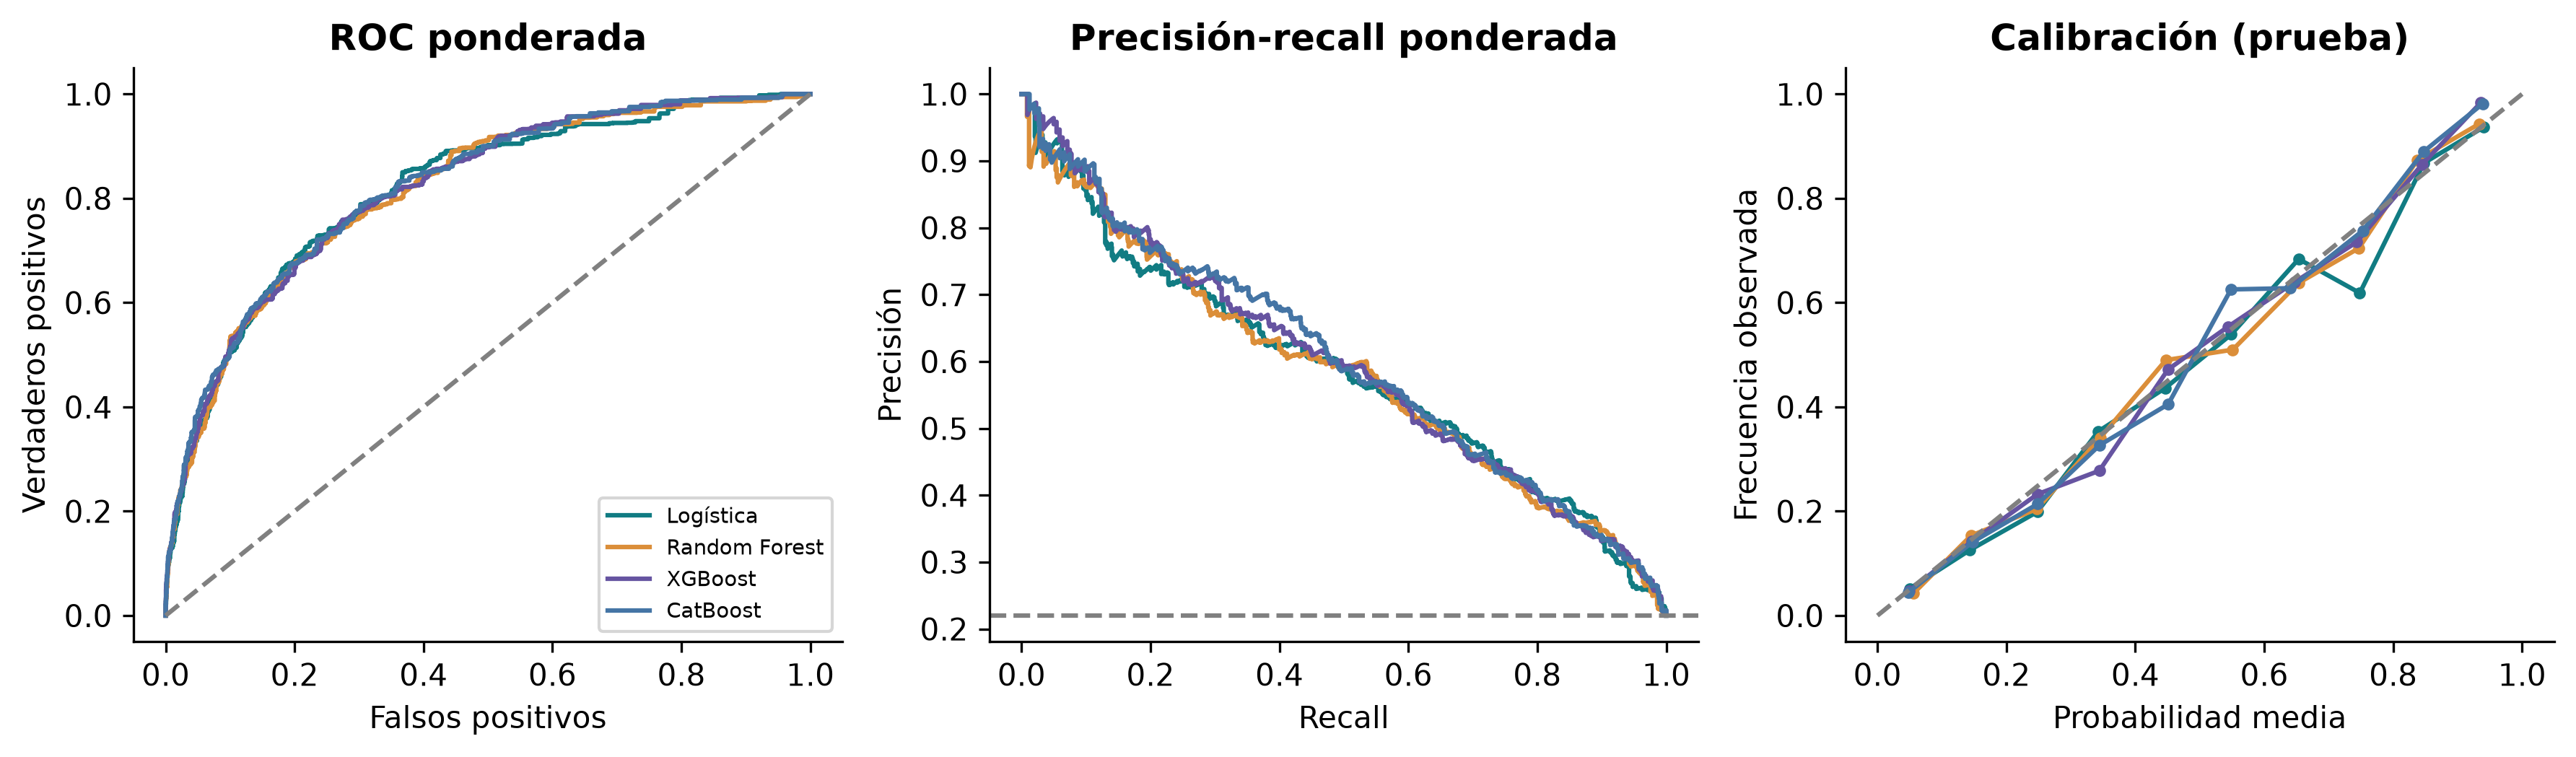

Figura: confusion_matrix.png | SHA-256: f27d7e202093be73121afd5b99f5a0e2b08ce4f88f4b763ae188ede84dd67e4d


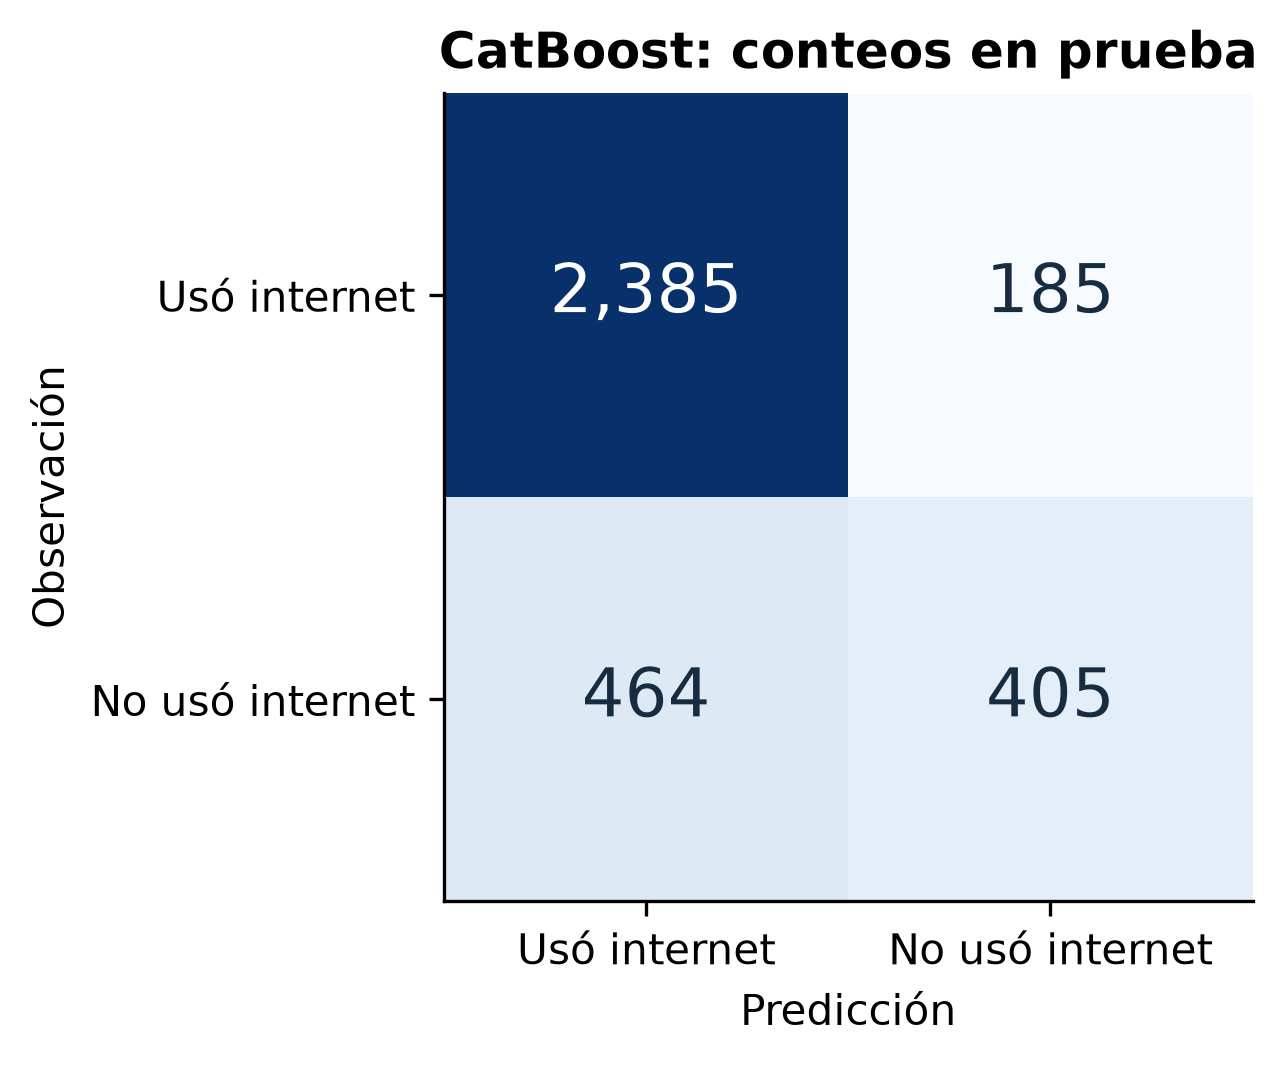

In [2]:
detail=audit('classification')
print('Ganador:',detail['winner'],'| Umbral:',detail['threshold'])
display(pd.DataFrame(detail['metrics']))
table('model_comparison_cv.csv')
table('model_comparison_test.csv')
table('weight_sensitivity.csv')
figure('model_curves.png')
figure('confusion_matrix.png')